# Embedding experiments

Goal: choose **how to represent a book** and **which embedding model** to use, with measurements on our own corpus.

1. Why a single "title + author + genres + synopsis" text is not enough
2. Benchmark: TF-IDF baseline vs 3 SBERT models x 3 representations
3. Adding the genres to the book vector
4. Queries with the final book vectors

In [1]:
# Make the project root importable (notebooks live in notebooks/)
import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

## Imports

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from transformers import AutoTokenizer

from src.data.data import load_config, load_books
from src.data.categories import load_categories
from src.nlp.embeddings import encode, fuse
from src.nlp.benchmark import run_benchmark, genre_fusion_benchmark, FINE_QUERIES

config = load_config(ROOT / "configs/data.yaml")
MODEL_NAME = config["embeddings"]["model"]
df, vectors = load_books(root=ROOT)
print(df.shape, {k: v.shape for k, v in vectors.items()})

(12040, 9) {'synopsis': (12040, 768), 'genres': (12040, 768), 'book': (12040, 768)}


## 1. Synopses are longer than the model window

SBERT models only read the first 256 (MiniLM) or 384 (mpnet) tokens: the rest of the text is **silently ignored**. Removing stop-words shortens the text but also removes the context SBERT relies on (negations, word order).

In [3]:
tok = AutoTokenizer.from_pretrained("sentence-transformers/all-MiniLM-L6-v2")
sample = df.sample(2000, random_state=0)
for name, col in [("raw synopsis", "synopsis_raw"), ("preprocessed synopsis", "synopsis")]:
    n = np.array([len(tok(t)["input_ids"]) for t in sample[col]])
    print(f"{name:22s} median {np.median(n):5.0f} tokens | p90 {np.percentile(n, 90):5.0f} | > 256 tokens: {100 * (n > 256).mean():.0f}%")

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (675 > 512). Running this sequence through the model will result in indexing errors


raw synopsis           median   358 tokens | p90  1305 | > 256 tokens: 62%


preprocessed synopsis  median   182 tokens | p90   655 | > 256 tokens: 39%


Mixing short fields in the same text is a second problem: in a first version (title + author + genres + synopsis in one text, MiniLM), the query *"A dark psychological novel about guilt and morality"* returned 4 books out of 5 whose **title** contains "Dark" — a lexical effect, not a thematic one. The synopsis and the genres are therefore encoded **separately** (and the title is left out); section 3 combines the two vectors.

## 2. Benchmark

Ground truth = macro-categories coming from the Freebase genres (books whose category was *predicted* are excluded). Only the synopsis is encoded, so that the model cannot read the label in the text.

| Metric | Meaning |
|---|---|
| `query_p_at_10` | 33 user-like queries (3 per category): share of the 10 closest books belonging to the target category. **Main task of the app.** |
| `centroid_acc` | Nearest-centroid classification (prototypes from half of the sample, tested on the other half) |
| `zero_shot_acc` | Nearest category *description* (no labeled example) |

Compared: **TF-IDF** (lexical baseline: word overlap only) and 3 SBERT models x 3 representations of the synopsis.

⚠️ ~1h on CPU for 1,500 books. Set `RUN_BENCHMARK = True` to recompute; otherwise the saved results are loaded.

In [4]:
RUN_BENCHMARK = False
RESULTS = ROOT / config["paths"]["benchmark_folder"] / "benchmark_results.csv"

if RUN_BENCHMARK or not RESULTS.exists():
    # Ground truth only for books labeled by their genres
    bench_df = df.copy()
    bench_df["categories"] = [c if src == "genres" else set()
                              for c, src in zip(bench_df["categories"], bench_df["category_source"])]
    results = run_benchmark(bench_df, load_categories(ROOT / "configs/categories.yaml"), n_books=1500, out_path=RESULTS)
    print("Random baseline p@10:", round(results.attrs["random_p_at_10"], 3))
else:
    results = pd.read_csv(RESULTS)

results["full_corpus_min"] = results["sec_per_1000_books"] * len(df) / 1000 / 60
results.round(3)

,model,representation,query_p_at_10,centroid_acc,zero_shot_acc,sec_per_1000_books,full_corpus_min
0,TF-IDF,preprocessed,0.433,0.700,0.323,3.106,0.623
1,all-MiniLM-L6-v2,raw (truncated),0.527,0.595,0.438,16.298,3.270
2,all-MiniLM-L6-v2,preprocessed,0.545,0.583,0.483,16.375,3.286
3,all-MiniLM-L6-v2,raw chunked (mean),0.552,0.587,0.429,66.523,13.349
4,multi-qa-MiniLM-L6-cos-v1,raw (truncated),0.500,0.585,0.364,33.291,6.680
5,multi-qa-MiniLM-L6-cos-v1,preprocessed,0.491,0.559,0.405,27.761,5.571
6,multi-qa-MiniLM-L6-cos-v1,raw chunked (mean),0.539,0.584,0.361,73.322,14.713
7,all-mpnet-base-v2,raw (truncated),0.555,0.648,0.384,183.261,36.774
8,all-mpnet-base-v2,preprocessed,0.552,0.628,0.467,142.965,28.688
9,all-mpnet-base-v2,raw chunked (mean),0.567,0.655,0.378,412.095,82.694


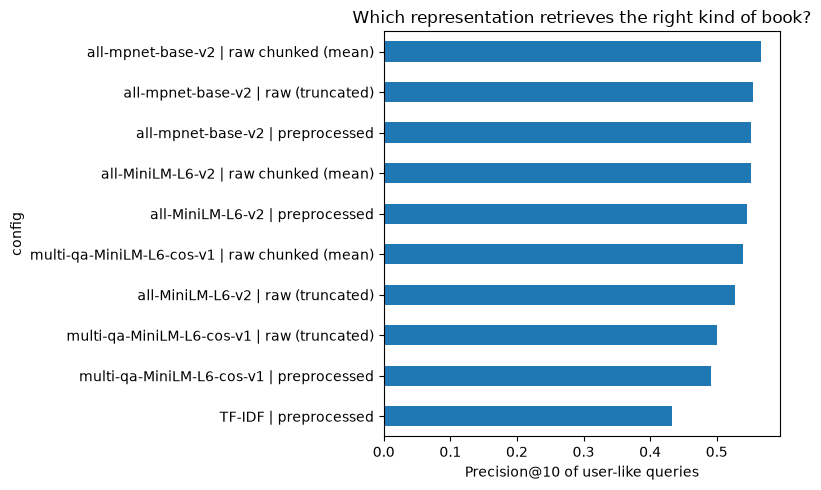

In [5]:
# Visual comparison of the main metric
ax = results.assign(config=results["model"] + " | " + results["representation"]) \
            .set_index("config")["query_p_at_10"].sort_values().plot.barh(figsize=(8, 5))
ax.set_xlabel("Precision@10 of user-like queries")
ax.set_title("Which representation retrieves the right kind of book?")
plt.tight_layout()

### Conclusions

Final run, 1,500 books, 33 queries (random choice: P@10 = 0.126).

- **Raw synopsis, chunked + mean is the best representation for retrieval, for every model** (MiniLM 0.552, multi-qa 0.539, mpnet 0.567): the whole summary is read and stays in natural language.
- The **preprocessed** text is not consistently worse than the truncated raw text: it fits more of the summary in the window (it helps MiniLM, 0.545 vs 0.527) but loses grammar and context (mpnet 0.552 vs 0.555). Chunking keeps both advantages.
- `multi-qa-MiniLM`, trained for question → passage search, brings nothing here.
- **`all-mpnet-base-v2` is the best model** on retrieval (0.567) and centroid classification (0.655). Its cost (≈ 3 h to encode the whole corpus on CPU) is paid once, since the vectors are stored. → **chosen configuration: `all-mpnet-base-v2`, raw chunked (mean)**.
- **TF-IDF** is far behind for retrieval (0.433, −13 points): matching a reader's description needs meaning, not word overlap. But it is the **best for nearest-centroid classification (0.700)**: choosing the theme of a book from its vocabulary is a lexical task. → TF-IDF centroids are used to categorize the books with vague genres; SBERT stays the engine for the reader's texts.
- Matching the category **descriptions** (zero-shot) is weak for every method (0.32–0.48): labelled examples (centroids) are needed.

## 3. Adding the genres to the book vector

The benchmark above measures whether the closest books are in the right **broad category** (11 of them). Testing the app with a precise wish showed the limit of a summary-only vector: a reader asking for *a society that controls its citizens through surveillance* did not get any dystopia. A Wikipedia plot summary tells **what happens** (*"Montag goes home, his wife Mildred…"*) but rarely names the **kind of book**, so long, detailed summaries of classic dystopias end up far from a thematic request.

In [6]:
q = encode([FINE_QUERIES["Dystopia"]], MODEL_NAME)[0]
print("Query:", FINE_QUERIES["Dystopia"], "\n")
for label, E in [("summary only", vectors["synopsis"]), ("summary + genres", vectors["book"])]:
    s = E @ q
    rank = (-s).argsort().argsort() + 1
    print(f"{label:17s}", " | ".join(f"{t}: rank {rank[df.index[df.title == t][0]]}"
                                      for t in ["Fahrenheit 451", "We", "The Handmaid's Tale"]))

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Query: A society that controls its citizens through surveillance and propaganda, with a hero who rebels against the system. 

summary only      Fahrenheit 451: rank 5504 | We: rank 632 | The Handmaid's Tale: rank 712
summary + genres  Fahrenheit 451: rank 3253 | We: rank 108 | The Handmaid's Tale: rank 549


**Fix:** each book's Freebase genre list is encoded as a short text (`"Genres: Dystopia, Science Fiction, …"`) and the book vector becomes $\text{normalize}\big((1-w)\cdot v_{\text{summary}} + w\cdot v_{\text{genres}}\big)$ — the cosine with a query is then (up to the norm) a weighted mean of its cosine with the summary and with the genres. The genres are encoded **apart** from the summary (a mixed text gave the title bias of section 1), and the title is never used.

**Test**, on the whole corpus (12,040 books):
- `subgenre_p_at_10`: 16 queries describing a precise Freebase sub-genre (dystopia, spy fiction, steampunk…) **without naming it**, share of the top 10 carrying that genre;
- `category_p_at_10`: the 33 category queries of section 2;
- `vague_share`: share of books with vague genres ("Fiction", "Novel") in these top 10.

⚠️ The genres are now both **in the vector and in the ground truth**: this is why the queries never contain the genre name. The gain still partly comes from the metadata itself, which is precisely its purpose.

In [7]:
FUSION = ROOT / config["paths"]["benchmark_folder"] / "genre_fusion_results.csv"
fusion = genre_fusion_benchmark(df, vectors["synopsis"], vectors["genres"], MODEL_NAME, out_path=FUSION)
fusion.round(3)

,genre_weight,subgenre_p_at_10,category_p_at_10,vague_share
0,0.00,0.188,0.521,0.224
1,0.25,0.312,0.658,0.178
2,0.50,0.488,0.873,0.076
3,0.75,0.500,0.921,0.039


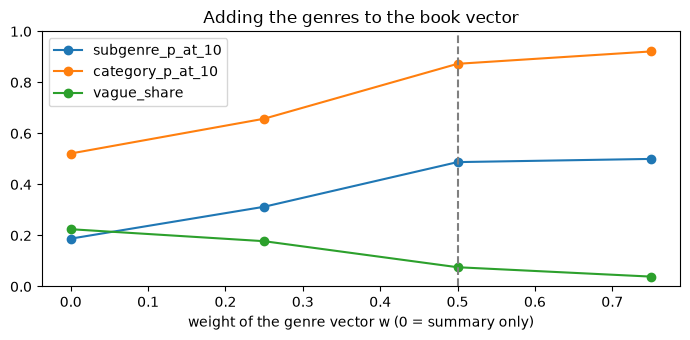

In [8]:
ax = fusion.set_index("genre_weight")[["subgenre_p_at_10", "category_p_at_10", "vague_share"]].plot(marker="o", figsize=(7, 3.5))
ax.axvline(config["embeddings"]["genre_weight"], ls="--", c="grey")
ax.set_xlabel("weight of the genre vector w (0 = summary only)"); ax.set_ylim(0, 1)
ax.set_title("Adding the genres to the book vector"); plt.tight_layout()

### Conclusions (genres)

Whole corpus (12,040 books), 16 sub-genre queries that never name the genre, 33 category queries.

- **Summary only (w = 0) misses precise themes:** sub-genre P@10 = 0.188. For the dystopia query, *Fahrenheit 451* ranks 5,504th and *We* 632nd: their summaries narrate the plot without naming the genre.
- **Adding the genres helps a lot:** with w = 0.5, sub-genre P@10 = **0.488** (×2.6) and category P@10 = **0.873** (0.521 before). *We* moves up to rank 108.
- **w = 0.75 is barely better (0.500 / 0.921)** but the genre list then dominates the summary: the vector would mostly repeat the metadata, and books with vague genres almost disappear from the results (3.9% of the top 10, against 22% without genres). → **chosen: w = 0.5** (summary and genres weigh the same; vague-genre books still 7.6% of the top 10).
- **Limits:** the genres are also the ground truth of this test (the queries never name them, but the gain partly comes from the metadata itself); books whose genres are only "Fiction" / "Novel" (~25%) gain nothing and are recommended less often.

## 4. Queries with the final book vectors

In [9]:
book_emb = vectors["book"]   # summary + genres (section 3)

queries = [
    "I want a dark psychological novel about guilt and morality",
    "An emotional science-fiction story exploring human relationships and artificial intelligence",
    "A classic romantic story with strong female characters and social criticism",
    "Epic fantasy with dragons, quests and friendship",
    "A quiet philosophical book about loneliness and the meaning of life"
]

In [10]:
def find_most_similar(query: str, top_k: int = 5) -> pd.DataFrame:
    """Return the top-k books whose vector (summary + genres) is the most similar to a free-text query."""
    query_emb = encode([query], MODEL_NAME)[0]
    # Vectors are L2-normalized, so the dot product IS the cosine similarity
    scores = book_emb @ query_emb
    top_indices = np.argsort(scores)[::-1][:top_k]

    return pd.DataFrame([{
        "rank": rank + 1,
        "title": df.iloc[idx]["title"],
        "author": df.iloc[idx]["author"],
        "categories": ", ".join(sorted(df.iloc[idx]["categories"])),
        "score": float(scores[idx]),
        "synopsis_preview": df.iloc[idx]["synopsis_raw"][:180] + "...",
    } for rank, idx in enumerate(top_indices)])

In [11]:
for q in queries:
    print("\n" + "=" * 80)
    print(f"QUERY: {q}")
    print("=" * 80)
    display(find_most_similar(q, top_k=5))


QUERY: I want a dark psychological novel about guilt and morality


,rank,title,author,categories,score,synopsis_preview
0,1,A Mind to Murder,P. D. James,Mystery & Crime,0.597685,"In a psychiatric clinic late one night, the p..."
1,2,Dr. Heidenhoff's Process,Edward Bellamy,Fantasy,0.597249,The novel concerns a doctor who develops a me...
2,3,Live Flesh,Ruth Rendell,Mystery & Crime,0.589273,"The novel's protagonist is Victor Jenner, sen..."
3,4,The Sand Dwellers,Adam Niswander,Horror & Gothic,0.585142,The novel is set in the Superstition Mountain...
4,5,Your Heart Belongs to Me,Dean Koontz,"Literary Fiction, Thriller & Suspense",0.581398,"The central character, Ryan Perry, is the wea..."



QUERY: An emotional science-fiction story exploring human relationships and artificial intelligence


,rank,title,author,categories,score,synopsis_preview
0,1,Waiting for the Galactic Bus,Parke Godwin,Science Fiction,0.468777,The tale begins with two college-age brothers...
1,2,Neighbors,Thomas Berger,Literary Fiction,0.464073,"Earl Keese is a middle-aged, middle-class sub..."
2,3,The Lover,Marguerite Duras,Literary Fiction,0.460815,Set against the backdrop of French colonial V...
3,4,The Pedestrian,Ray Bradbury,Science Fiction,0.459482,"In this story we encounter Leonard Mead, a ci..."
4,5,Feuchtgebiete,Charlotte Roche,Literary Fiction,0.459360,"Set in an anonymous German city, Feuchtgebiet..."



QUERY: A classic romantic story with strong female characters and social criticism


,rank,title,author,categories,score,synopsis_preview
0,1,Fire in Stubble,Baroness Emma Orczy,Romance,0.571958,The book centres on the love life of Rose Mar...
1,2,La Anam,Ihsan Abdel Quddous,"Literary Fiction, Romance",0.564028,"The novel's main character, Nadia, is a spoil..."
2,3,A Political Romance,Laurence Sterne,Romance,0.563833,"This, though necessary, is not sufficient to ..."
3,4,Home of the Gentry,Ivan Turgenev,Romance,0.563259,The novel's protagonist is Fyodor Ivanych Lav...
4,5,Mauprat,George Sand,Romance,0.560545,The novel's plot has been called a plot of fe...



QUERY: Epic fantasy with dragons, quests and friendship


,rank,title,author,categories,score,synopsis_preview
0,1,The Last Dragonslayer,Jasper Fforde,Fantasy,0.573232,The story begins with 15-year-old Jennifer St...
1,2,Quest for Lost Heroes,David Gemmell,Fantasy,0.572294,The Drenai fortress of Dros Delnoch has falle...
2,3,The Knight,Gene Wolfe,Fantasy,0.570806,The story opens with an older narrator recoun...
3,4,Durandal,Harold Lamb,Fantasy,0.568249,"A Crusader, betrayed by a scheming emperor an..."
4,5,Love and War,Margaret Weis,Fantasy,0.564666,The book is a compilation of 10 short stories...



QUERY: A quiet philosophical book about loneliness and the meaning of life


,rank,title,author,categories,score,synopsis_preview
0,1,The Outsider,Colin Wilson,"Literary Fiction, Non-fiction",0.517221,The book is still published with enthusiastic...
1,2,A Happy Death,Albert Camus,Literary Fiction,0.505035,The novel has just over 100 pages and consist...
2,3,Nausea,Jean-Paul Sartre,Non-fiction,0.499517,"Written in the form of journal entries, it fo..."
3,4,The Fall,Albert Camus,Literary Fiction,0.488440,The novel opens with Clamence sitting in the ...
4,5,Youth: Scenes from Provincial Life II,John Maxwell Coetzee,Literary Fiction,0.483145,"After graduating in mathematics and English, ..."
